In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Mutation": root / "Mutation",
    "Crossover_95": root / "Crossover",
}
dataframes=[]
for source_name, folder in sources.items():
    if source_name == "Crossover_95":
        matching_folders = [
            path for path in folder.rglob("*")
            if path.is_dir() and path.name.endswith("95")
        ]

        csv_files = sorted({
            csv_file
            for matching_folder in matching_folders
            for csv_file in matching_folder.rglob("*.csv")
        })
    else:
        csv_files = sorted(folder.rglob("*.csv"))
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

In [3]:
df_M03_Mutation=df_all[df_all["model_id"]=="M03"].copy()
df_M03_Mutation_summary=(df_M03_Mutation.groupby(["grid_rows", "pm", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
))
display(df_M03_Mutation_summary)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.513333,2.500000,2.600000,0.034575,30
1,10,0.01,Maze,3.338889,3.333333,3.500000,0.030429,30
2,10,0.01,Random,2.598611,2.416667,2.785714,0.148158,60
3,10,0.03,Cluster,2.506667,2.500000,2.600000,0.025371,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
5,10,0.03,Random,2.587103,2.416667,2.785714,0.156183,60
6,10,0.05,Cluster,2.520000,2.500000,2.600000,0.040684,30
7,10,0.05,Maze,3.344444,3.333333,3.500000,0.042285,30
8,10,0.05,Random,2.599603,2.416667,2.857143,0.163465,60
9,20,0.01,Cluster,4.790090,4.783784,4.810811,0.011627,30


In [4]:
table_random = (
    df_M03_Mutation_summary[df_M03_Mutation_summary["map_type"] == "Random"]
    .sort_values("pm")
)

display(table_random)
table_maze = (
    df_M03_Mutation_summary[df_M03_Mutation_summary["map_type"] == "Maze"]
    .sort_values("pm")
)

display(table_maze)
table_cluster = (
    df_M03_Mutation_summary[df_M03_Mutation_summary["map_type"] == "Cluster"]
    .sort_values("pm")
)

display(table_cluster)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.01,Random,2.598611,2.416667,2.785714,0.148158,60
11,20,0.01,Random,6.247874,6.025000,6.487179,0.217490,60
20,40,0.01,Random,6.681822,6.525641,6.856250,0.101881,60
5,10,0.03,Random,2.587103,2.416667,2.785714,0.156183,60
23,40,0.03,Random,6.664794,6.512821,6.868750,0.106314,60
14,20,0.03,Random,6.244947,6.025000,6.487179,0.219420,60
8,10,0.05,Random,2.599603,2.416667,2.857143,0.163465,60
17,20,0.05,Random,6.247885,6.025000,6.512821,0.218402,60
26,40,0.05,Random,6.661127,6.519231,6.831250,0.103522,60


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.01,Maze,3.338889,3.333333,3.500000,0.030429,30
10,20,0.01,Maze,6.807692,6.794872,6.846154,0.014676,30
19,40,0.01,Maze,6.936092,6.848276,7.179310,0.064618,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
22,40,0.03,Maze,6.896782,6.834483,6.979310,0.043861,30
13,20,0.03,Maze,6.812821,6.794872,6.846154,0.015281,30
7,10,0.05,Maze,3.344444,3.333333,3.500000,0.042285,30
16,20,0.05,Maze,6.808547,6.794872,6.820513,0.013011,30
25,40,0.05,Maze,6.875862,6.834483,6.944828,0.036041,30


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.513333,2.500000,2.600000,0.034575,30
9,20,0.01,Cluster,4.790090,4.783784,4.810811,0.011627,30
18,40,0.01,Cluster,5.513978,5.451613,5.645161,0.046348,30
3,10,0.03,Cluster,2.506667,2.500000,2.600000,0.025371,30
21,40,0.03,Cluster,5.488387,5.451613,5.567742,0.032019,30
12,20,0.03,Cluster,4.788288,4.783784,4.810811,0.010245,30
6,10,0.05,Cluster,2.520000,2.500000,2.600000,0.040684,30
15,20,0.05,Cluster,4.785586,4.783784,4.810811,0.006857,30
24,40,0.05,Cluster,5.477634,5.445161,5.600000,0.031809,30


In [5]:
df_M03_Mutation_summary["rank_mean_cost"] = (
    df_M03_Mutation_summary
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M03 = (
    df_M03_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M03)

,pm,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.05,2.000000,5.035632,0.072897,9
1,0.03,1.666667,5.035902,0.067633,9
0,0.01,2.333333,5.047598,0.074422,9


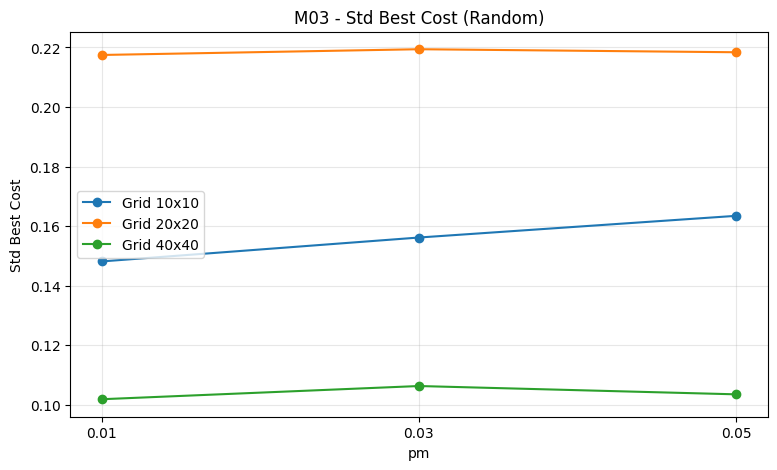

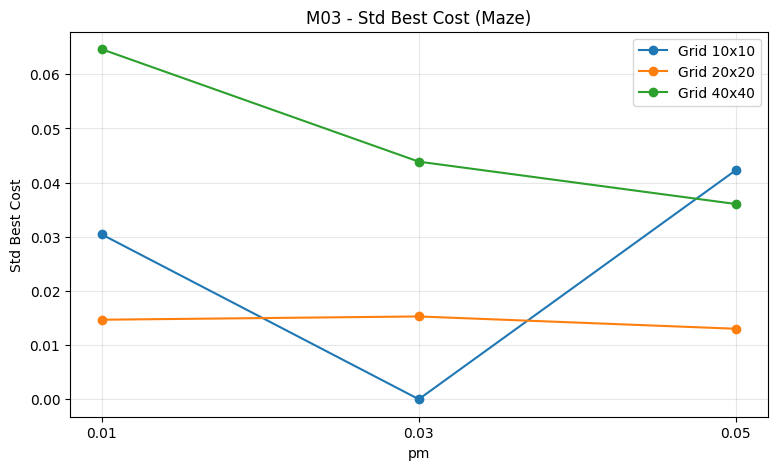

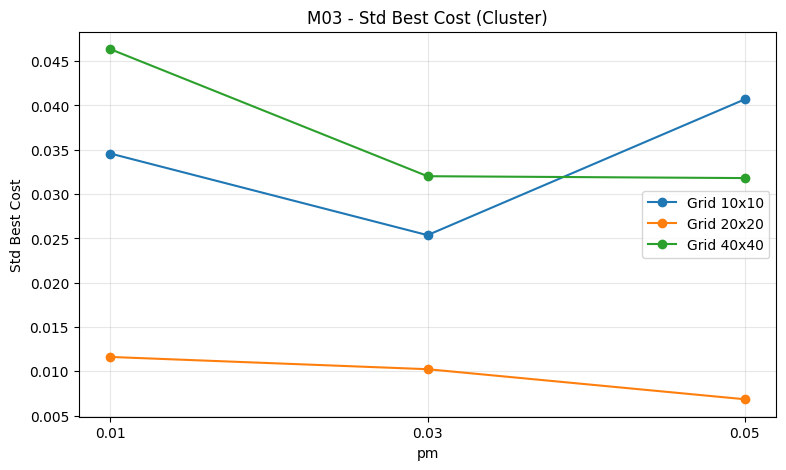

In [6]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_M03_Mutation_summary[
        df_M03_Mutation_summary["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pm")
        )

        plt.plot(
            data_size["pm"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M03 - Std Best Cost ({map_type})")
    plt.xlabel("pm")
    plt.ylabel("Std Best Cost")
    plt.xticks(sorted(data["pm"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [7]:
#rank std cost
df_M03_Mutation_summary["rank_std_cost"] = (
    df_M03_Mutation_summary
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M03_std = (
    df_M03_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_M03_std)


     pm  avg_rank_std  avg_std_cost  jumlah_kombinasi
2  0.05      1.888889      0.072897                 9
0  0.01      2.000000      0.074422                 9
1  0.03      2.111111      0.067633                 9


In [8]:
summary_M03_time=(df_M03_Mutation.groupby(["grid_rows","pm", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M03_time)
avg_time_by_population_m03 = (
    summary_M03_time.groupby("pm", as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values("avg_execTime")
)
display(avg_time_by_population_m03)
summary_time_pivot = summary_M03_time.pivot(
    index=["grid_rows", "pm"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M03_time.groupby(["map_type", "pm"], as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pm,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.01,Cluster,19.800000,10,31,5.523617,30
1,10,0.01,Maze,14.400000,8,21,3.286335,30
2,10,0.01,Random,21.716667,10,38,6.874398,60
3,10,0.03,Cluster,20.566667,10,34,5.986671,30
4,10,0.03,Maze,16.300000,9,25,3.905346,30
5,10,0.03,Random,24.816667,9,44,8.557862,60
6,10,0.05,Cluster,20.433333,11,32,5.544076,30
7,10,0.05,Maze,17.600000,11,27,4.263720,30
8,10,0.05,Random,22.300000,9,40,7.529152,60
9,20,0.01,Cluster,95.900000,58,128,15.385506,30


,pm,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.01,552.029630,117.076430,9
2,0.05,607.703704,97.753924,9
1,0.03,666.529630,131.393249,9


map_type            Cluster         Maze       Random
grid_rows pm                                         
10        0.01    19.800000    14.400000    21.716667
          0.03    20.566667    16.300000    24.816667
          0.05    20.433333    17.600000    22.300000
20        0.01    95.900000    94.200000   100.333333
          0.03    94.800000   114.166667   100.116667
          0.05   101.333333   119.966667   101.033333
40        0.01  1318.900000  1631.733333  1671.283333
          0.03  1904.833333  1732.766667  1990.400000
          0.05  1748.500000  1565.800000  1772.366667

  map_type    pm  avg_execTime  avg_std_time  jumlah_kombinasi
0  Cluster  0.01    478.200000    126.625931                 3
2  Cluster  0.05    623.422222     93.094589                 3
1  Cluster  0.03    673.400000    164.823453                 3
5     Maze  0.05    567.788889     95.711981                 3
3     Maze  0.01    580.111111     99.540742                 3
4     Maze  0.03    621.077778     78.320830                 3
6   Random  0.01    597.777778    125.062616                 3
8   Random  0.05    631.900000    104.455201                 3
7   Random  0.03    705.111111    151.035464                 3
